# Machine Learning Zoom Camp Classification Evaluation Metrics

In [2]:
import numpy as np
import pandas as pd

In [13]:
# Q1
np.__version__

'2.0.1'

In [4]:

df = pd.read_csv("course_lead_scoring_2026.csv")

In [18]:
# 1. Check for missing values in each feature
print("Missing values before preparation:")
print(df.isnull().sum())

# 2. Identify categorical and numerical columns
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

numerical_columns = df.select_dtypes(
    include=["number"]
).columns

# 3. Replace missing categorical values with 'NA'
df[categorical_columns] = df[categorical_columns].fillna("NA")

# 4. Replace missing numerical values with 0.0
df[numerical_columns] = df[numerical_columns].fillna(0.0)

# 5. Verify that no missing values remain
print("\nMissing values after preparation:")
print(df.isnull().sum())

# 6. Split the data into train, validation, and test sets
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

# 7. Check the sizes of the resulting datasets
print("\nDataset sizes:")
print("Full dataset:", len(df))
print("Training set:", len(df_train))
print("Validation set:", len(df_val))
print("Test set:", len(df_test))

Missing values before preparation:
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Missing values after preparation:
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Dataset sizes:
Full dataset: 5000
Training set: 3000
Validation set: 1000
Test set: 1000


In [19]:
from sklearn.metrics import roc_auc_score

numerical_variables = [
    'annual_income',
    'number_of_courses_viewed',
    'interaction_count',
    'lead_score'
]

for variable in numerical_variables:
    auc = roc_auc_score(df_train['converted'], df_train[variable])

    if auc < 0.5:
        auc = roc_auc_score(df_train['converted'], -df_train[variable])

    print(variable, round(auc, 4))

annual_income 0.6082
number_of_courses_viewed 0.723
interaction_count 0.7649
lead_score 0.7882


In [20]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Separate features and target
y_train = df_train['converted'].values
y_val = df_val['converted'].values

# Convert dataframes to dictionaries
train_dicts = df_train.drop('converted', axis=1).to_dict(orient='records')
val_dicts = df_val.drop('converted', axis=1).to_dict(orient='records')

# One-hot encoding
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Train logistic regression
model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)
model.fit(X_train, y_train)

# Predict probabilities on validation data
y_pred = model.predict_proba(X_val)[:, 1]

# Calculate validation AUC
auc = roc_auc_score(y_val, y_pred)
print(round(auc, 3))

0.732


Matplotlib is building the font cache; this may take a moment.


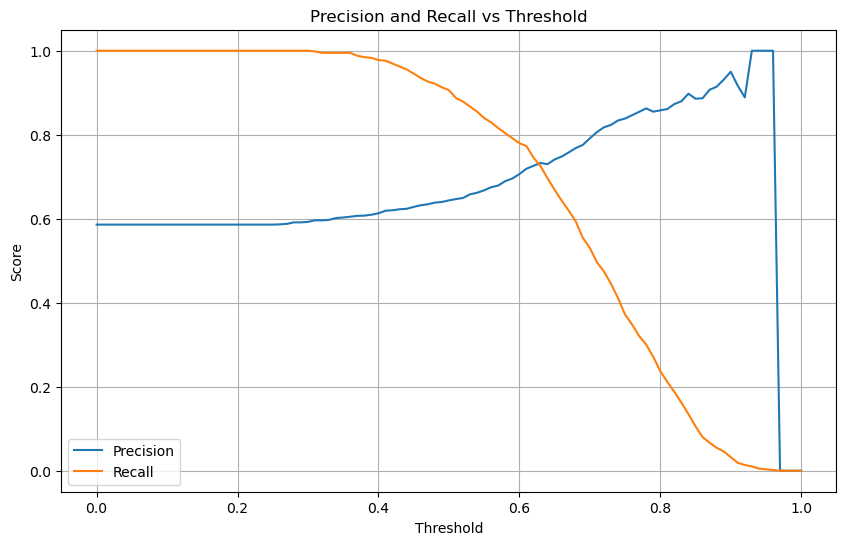

Best threshold: 0.63
Precision: 0.733
Recall: 0.725
Absolute difference: 0.008


In [21]:

import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

# Get predicted probabilities from the trained model
y_pred = model.predict_proba(X_val)[:, 1]

# Evaluate thresholds from 0.00 to 1.00
thresholds = np.arange(0.0, 1.01, 0.01)

results = []

for threshold in thresholds:
    y_pred_binary = (y_pred >= threshold).astype(int)

    precision = precision_score(
        y_val, y_pred_binary, zero_division=0
    )
    recall = recall_score(
        y_val, y_pred_binary, zero_division=0
    )

    results.append({
        'threshold': threshold,
        'precision': precision,
        'recall': recall
    })

# Store results in a DataFrame
df_scores = pd.DataFrame(results)

# Plot precision and recall
plt.figure(figsize=(10, 6))
plt.plot(
    df_scores['threshold'],
    df_scores['precision'],
    label='Precision'
)
plt.plot(
    df_scores['threshold'],
    df_scores['recall'],
    label='Recall'
)
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)
plt.show()

# Ignore thresholds where both metrics are zero
valid = ~(
    (df_scores['precision'] == 0) &
    (df_scores['recall'] == 0)
)

df_valid = df_scores[valid].copy()

# Find threshold with the smallest absolute difference
df_valid['difference'] = abs(
    df_valid['precision'] - df_valid['recall']
)

best = df_valid.loc[df_valid['difference'].idxmin()]

print("Best threshold:", round(best['threshold'], 2))
print("Precision:", round(best['precision'], 3))
print("Recall:", round(best['recall'], 3))
print("Absolute difference:", round(best['difference'], 3))


In [22]:
# Get predicted probabilities from the trained model
y_pred = model.predict_proba(X_val)[:, 1]

# Generate thresholds from 0.00 to 1.00
thresholds = np.arange(0.0, 1.01, 0.01)

results = []

for threshold in thresholds:
    y_pred_binary = (y_pred >= threshold).astype(int)

    precision = precision_score(
        y_val, y_pred_binary, zero_division=0
    )
    recall = recall_score(
        y_val, y_pred_binary, zero_division=0
    )

    # Compute F1 score
    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0.0

    results.append({
        'threshold': threshold,
        'precision': precision,
        'recall': recall,
        'f1': f1
    })

# Create a DataFrame with the results
df_f1 = pd.DataFrame(results)

# Find the threshold with the maximum F1 score
best = df_f1.loc[df_f1['f1'].idxmax()]

print("Best threshold:", round(best['threshold'], 2))
print("Maximum F1 score:", round(best['f1'], 3))
print("Precision:", round(best['precision'], 3))
print("Recall:", round(best['recall'], 3))


Best threshold: 0.41
Maximum F1 score: 0.758
Precision: 0.619
Recall: 0.976


In [23]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    del df_train['converted']
    del df_val['converted']

    dv = DictVectorizer(sparse=False)

    train_dict = df_train.to_dict(orient='records')
    val_dict = df_val.to_dict(orient='records')

    X_train = dv.fit_transform(train_dict)
    X_val = dv.transform(val_dict)

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )

    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print("AUC scores:", scores)
print("Standard deviation:", np.std(scores))

AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Standard deviation: 0.006853233151022138


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer

C_values = [0.000001, 0.001, 1]

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

for C in C_values:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx].copy()
        df_val = df_full_train.iloc[val_idx].copy()

        y_train = df_train["converted"].values
        y_val = df_val["converted"].values

        df_train = df_train.drop(columns=["converted"])
        df_val = df_val.drop(columns=["converted"])

        dv = DictVectorizer(sparse=False)

        X_train = dv.fit_transform(
            df_train.to_dict(orient="records")
        )
        X_val = dv.transform(
            df_val.to_dict(orient="records")
        )

        model = LogisticRegression(
            solver="liblinear",
            C=C,
            max_iter=1000
        )

        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print(
        f"C={C}: mean AUC={np.mean(scores):.3f}, "
        f"std={np.std(scores):.3f}"
    )

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007
